In [ ]:
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio as rio
from matplotlib import pyplot as plt
import seaborn as sns
from cartopy import feature as cf
from cartopy import crs as ccrs
from matplotlib.colors import BoundaryNorm, LinearSegmentedColormap
from matplotlib.patches import Patch, Rectangle
from matplotlib.ticker import FuncFormatter
from matplotlib.colors import rgb2hex
from matplotlib.colors import to_rgb
from generativepy.color import Color
from PIL import ImageColor
from tqdm import tqdm
from pathlib import Path

In [ ]:
names = locals()

In [ ]:
ROOT    = Path('..')
DATA    = ROOT / 'data'
RESULTS = ROOT / 'results'
FIGURES = ROOT / 'figures'

In [ ]:
country_raster_50km_ = rio.open(RESULTS / 'country-rasters' / 'country-raster-eck4-50km.tif')
country_raster_50km = country_raster_50km_.read(1)

In [ ]:
country_pseudo_values = pd.read_csv(DATA / 'country-pseudo-values.csv')
df_cement_production = pd.read_csv(DATA / 'production-142.csv', index_col=0)
economies_142 = df_cement_production.columns.tolist()

In [ ]:
world_map      = gpd.read_file(DATA / 'simplified-world-map/world-map.shp')
world_map      = world_map.drop([31])
world_map_eck4 = world_map.to_crs('ESRI:54012')

compile results for aggregate extraction

In [ ]:
# Economy-first annual percentile aggregation, shared by bars, text and Source Data.
# Keep percentile summaries for bars and separate global draw arrays for gray points.
extraction_percentile_cache = {}
extraction_global_draw_cache = {}
extraction_local_details = []

def compile_material_percentile_summaries(the_var):
    if the_var in extraction_percentile_cache:
        return extraction_percentile_cache[the_var]
    scenarios = ['BAU', 'MIU', 'LE', 'RE', 'RC', 'SS', 'CCR', 'CE']
    flow_root = Path(r'F:\aggregates-mining-biodiversity\results\material-flows')
    result = {s: {measure: np.zeros((3, 28), dtype=float)
                  for measure in ['absolute', 'reduction']} for s in scenarios}
    # Preserve the original draw-wise aggregation for the gray point cloud.
    # Its distribution is distinct from the sums of local percentile bounds.
    global_draws = {s: np.zeros((10000, 28), dtype=np.float64) for s in scenarios}
    material = the_var.removesuffix('_extraction')
    for economy in tqdm(economies_142, desc=material + ' economy-first percentiles'):
        with np.load(flow_root / economy / 'BAU' / f'{the_var}.npz') as data:
            baseline = data['data'].astype(np.float64)
        for scenario in scenarios:
            if scenario == 'BAU':
                values = baseline
            else:
                with np.load(flow_root / economy / scenario / f'{the_var}.npz') as data:
                    values = data['data'].astype(np.float64)
            if values.shape != (10000, 28) or not np.isfinite(values).all():
                raise ValueError(f'Invalid draws: {economy}/{scenario}/{the_var}')
            global_draws[scenario] += baseline if scenario == 'BAU' else baseline - values
            absolute = np.percentile(values, [2.5, 50, 97.5], axis=0)
            reduction = (np.zeros((3, 28)) if scenario == 'BAU' else
                         np.percentile(baseline - values, [2.5, 50, 97.5], axis=0))
            result[scenario]['absolute'] += absolute
            result[scenario]['reduction'] += reduction
            extraction_local_details.append([scenario, economy, material,
                *(absolute.sum(axis=1) / 1e6).tolist(), *(reduction.sum(axis=1) / 1e6).tolist()])
    extraction_global_draw_cache[the_var] = global_draws
    extraction_percentile_cache[the_var] = result
    return result

def compile_all_country_extraction(scenario, the_var):
    return compile_material_percentile_summaries(the_var)[scenario]['absolute']


In [ ]:
def compile_all_country_reduction(scenario, the_var):
    # Pair BAU and scenario draws within each economy/material/year BEFORE
    # taking local percentiles. Then sum matching endpoints over economies.
    return compile_material_percentile_summaries(the_var)[scenario]['reduction']


In [ ]:
sand_extraction_BAU = compile_all_country_extraction('BAU', 'sand_extraction')
sand_extraction_MIU = compile_all_country_extraction('MIU', 'sand_extraction')
sand_extraction_LE  = compile_all_country_extraction('LE', 'sand_extraction')
sand_extraction_RE  = compile_all_country_extraction('RE', 'sand_extraction')
sand_extraction_RC  = compile_all_country_extraction('RC', 'sand_extraction')
sand_extraction_SS  = compile_all_country_extraction('SS', 'sand_extraction')
sand_extraction_CCR = compile_all_country_extraction('CCR', 'sand_extraction')
sand_extraction_CE  = compile_all_country_extraction('CE', 'sand_extraction')

In [ ]:
gravel_extraction_BAU = compile_all_country_extraction('BAU', 'gravel_extraction')
gravel_extraction_MIU = compile_all_country_extraction('MIU', 'gravel_extraction')
gravel_extraction_LE  = compile_all_country_extraction('LE', 'gravel_extraction')
gravel_extraction_RE  = compile_all_country_extraction('RE', 'gravel_extraction')
gravel_extraction_RC  = compile_all_country_extraction('RC', 'gravel_extraction')
gravel_extraction_SS  = compile_all_country_extraction('SS', 'gravel_extraction')
gravel_extraction_CCR = compile_all_country_extraction('CCR', 'gravel_extraction')
gravel_extraction_CE  = compile_all_country_extraction('CE', 'gravel_extraction')

In [ ]:
limestone_extraction_BAU = compile_all_country_extraction('BAU', 'limestone_extraction')
limestone_extraction_MIU = compile_all_country_extraction('MIU', 'limestone_extraction')
limestone_extraction_LE  = compile_all_country_extraction('LE', 'limestone_extraction')
limestone_extraction_RE  = compile_all_country_extraction('RE', 'limestone_extraction')
limestone_extraction_RC  = compile_all_country_extraction('RC', 'limestone_extraction')
limestone_extraction_SS  = compile_all_country_extraction('SS', 'limestone_extraction')
limestone_extraction_CCR = compile_all_country_extraction('CCR', 'limestone_extraction')
limestone_extraction_CE  = compile_all_country_extraction('CE', 'limestone_extraction')

In [ ]:
sand_extraction_reduction_BAU = compile_all_country_reduction('BAU', 'sand_extraction')
sand_extraction_reduction_MIU = compile_all_country_reduction('MIU', 'sand_extraction')
sand_extraction_reduction_LE  = compile_all_country_reduction('LE', 'sand_extraction')
sand_extraction_reduction_RE  = compile_all_country_reduction('RE', 'sand_extraction')
sand_extraction_reduction_RC  = compile_all_country_reduction('RC', 'sand_extraction')
sand_extraction_reduction_SS  = compile_all_country_reduction('SS', 'sand_extraction')
sand_extraction_reduction_CCR = compile_all_country_reduction('CCR', 'sand_extraction')
sand_extraction_reduction_CE  = compile_all_country_reduction('CE', 'sand_extraction')

In [ ]:
gravel_extraction_reduction_BAU = compile_all_country_reduction('BAU', 'gravel_extraction')
gravel_extraction_reduction_MIU = compile_all_country_reduction('MIU', 'gravel_extraction')
gravel_extraction_reduction_LE  = compile_all_country_reduction('LE', 'gravel_extraction')
gravel_extraction_reduction_RE  = compile_all_country_reduction('RE', 'gravel_extraction')
gravel_extraction_reduction_RC  = compile_all_country_reduction('RC', 'gravel_extraction')
gravel_extraction_reduction_SS  = compile_all_country_reduction('SS', 'gravel_extraction')
gravel_extraction_reduction_CCR = compile_all_country_reduction('CCR', 'gravel_extraction')
gravel_extraction_reduction_CE  = compile_all_country_reduction('CE', 'gravel_extraction')

In [ ]:
limestone_extraction_reduction_BAU = compile_all_country_reduction('BAU', 'limestone_extraction')
limestone_extraction_reduction_MIU = compile_all_country_reduction('MIU', 'limestone_extraction')
limestone_extraction_reduction_LE  = compile_all_country_reduction('LE', 'limestone_extraction')
limestone_extraction_reduction_RE  = compile_all_country_reduction('RE', 'limestone_extraction')
limestone_extraction_reduction_RC  = compile_all_country_reduction('RC', 'limestone_extraction')
limestone_extraction_reduction_SS  = compile_all_country_reduction('SS', 'limestone_extraction')
limestone_extraction_reduction_CCR = compile_all_country_reduction('CCR', 'limestone_extraction')
limestone_extraction_reduction_CE  = compile_all_country_reduction('CE', 'limestone_extraction')

In [ ]:
total_extraction_BAU = sand_extraction_BAU + gravel_extraction_BAU + limestone_extraction_BAU
total_extraction_MIU = sand_extraction_MIU + gravel_extraction_MIU + limestone_extraction_MIU
total_extraction_LE  = sand_extraction_LE  + gravel_extraction_LE  + limestone_extraction_LE
total_extraction_RE  = sand_extraction_RE  + gravel_extraction_RE  + limestone_extraction_RE
total_extraction_RC  = sand_extraction_RC  + gravel_extraction_RC  + limestone_extraction_RC
total_extraction_SS  = sand_extraction_SS  + gravel_extraction_SS  + limestone_extraction_SS
total_extraction_CCR = sand_extraction_CCR + gravel_extraction_CCR + limestone_extraction_CCR
total_extraction_CE  = sand_extraction_CE  + gravel_extraction_CE  + limestone_extraction_CE

In [ ]:
total_reduction_BAU = sand_extraction_reduction_BAU + gravel_extraction_reduction_BAU + limestone_extraction_reduction_BAU
total_reduction_MIU = sand_extraction_reduction_MIU + gravel_extraction_reduction_MIU + limestone_extraction_reduction_MIU
total_reduction_LE  = sand_extraction_reduction_LE  + gravel_extraction_reduction_LE  + limestone_extraction_reduction_LE
total_reduction_RE  = sand_extraction_reduction_RE  + gravel_extraction_reduction_RE  + limestone_extraction_reduction_RE
total_reduction_RC  = sand_extraction_reduction_RC  + gravel_extraction_reduction_RC  + limestone_extraction_reduction_RC
total_reduction_SS  = sand_extraction_reduction_SS  + gravel_extraction_reduction_SS  + limestone_extraction_reduction_SS
total_reduction_CCR = sand_extraction_reduction_CCR + gravel_extraction_reduction_CCR + limestone_extraction_reduction_CCR
total_reduction_CE  = sand_extraction_reduction_CE  + gravel_extraction_reduction_CE  + limestone_extraction_reduction_CE

In [ ]:
extraction_reduction = pd.DataFrame([], index=['BAU', 'MIU', 'LE', 'RE', 'RC', 'SS', 'CCR', 'CE'], columns=['sand_l', 'sand', 'sand_u', 'gravel_l', 'gravel', 'gravel_u', 'limestone_l', 'limestone', 'limestone_u', 'total_l', 'total', 'total_u', 'reduction_l', 'reduction', 'reduction_u'])

# Each input is already a 3 x 28 sum of economy-specific annual percentiles.
# Sum years and materials without taking another percentile of these summaries.
for material in ['sand', 'gravel', 'limestone', 'total']:
    for scenario in extraction_reduction.index:
        extraction_reduction.loc[scenario, [material + '_l', material, material + '_u']] = (
            names[f'{material}_extraction_{scenario}'].sum(axis=1) / 1e6)
for scenario in extraction_reduction.index:
    extraction_reduction.loc[scenario, ['reduction_l', 'reduction', 'reduction_u']] = (
        names[f'total_reduction_{scenario}'].sum(axis=1) / 1e6)
extraction_reduction = extraction_reduction.astype(float)
extraction_economy_summaries = pd.DataFrame(extraction_local_details, columns=[
    'scenario', 'economy', 'material', 'absolute_l', 'absolute', 'absolute_u',
    'reduction_l', 'reduction', 'reduction_u'])
# Gray points retain the original 10,000 draw-wise global outcomes (Gt).
# They do not define the economy-first bar heights or error-bar endpoints above.
extraction_plot_draws = pd.DataFrame({
    scenario: (extraction_global_draw_cache['sand_extraction'][scenario]
               + extraction_global_draw_cache['gravel_extraction'][scenario]
               + extraction_global_draw_cache['limestone_extraction'][scenario]).sum(axis=1) / 1e6
    for scenario in extraction_reduction.index
})
extraction_plot_draws.index = pd.RangeIndex(1, len(extraction_plot_draws) + 1, name='draw_id')
assert extraction_plot_draws.shape == (10000, 8)
assert np.isfinite(extraction_plot_draws.to_numpy()).all()


In [ ]:
RESULTS = ROOT / 'results'
extraction_reduction.to_csv(RESULTS / 'Data-for-Fig-2a.csv')
extraction_economy_summaries.to_csv(RESULTS / 'Data-for-Fig-2a-economy-summaries.csv', index=False)
extraction_plot_draws.to_csv(RESULTS / 'Data-for-Fig-2a-draws.csv')


In [ ]:
for material in ['sand', 'gravel', 'limestone']:
    for scenario in ['BAU', 'CE']:
        # names[f'{material}_demand_2023_2050_{scenario}_50km'] = rio.open(f'../results/demand-rasters/{material}-demand-2023-2050-{scenario}-50km.tif').read(1)
        names[f'{material}_demand_2023_2050_{scenario}_50km'] = rio.open(RESULTS / 'extraction-rasters' / f'{material}-extraction-demand-2023-2050-{scenario}-50km-M.tif').read(1)

total_demand_2023_2050_BAU_50km = sand_demand_2023_2050_BAU_50km + gravel_demand_2023_2050_BAU_50km + limestone_demand_2023_2050_BAU_50km
total_demand_2023_2050_CE_50km  = sand_demand_2023_2050_CE_50km + gravel_demand_2023_2050_CE_50km + limestone_demand_2023_2050_CE_50km


supplement_by_country = {}
economy_codes = pd.read_csv(RESULTS / 'pseudo-codes-economies-142.csv').drop_duplicates('value').set_index('value')['economies_142']
country_codes = country_pseudo_values.set_index('country')['value']
for scenario in ['BAU', 'CE']:
    supplement_by_country[scenario] = {}
    for material in ['sand', 'gravel', 'limestone']:
        with rio.open(RESULTS / 'extraction-rasters' / f'{material}-extraction-demand-2023-2050-{scenario}-50km-M-supplement.tif') as src:
            for band, code in enumerate(src.descriptions, 1):
                country = int(country_codes[economy_codes[int(code)]])
                supplement_by_country[scenario][country] = supplement_by_country[scenario].get(country, 0) + src.read(band).astype(np.float64)
base_demand_BAU = total_demand_2023_2050_BAU_50km.astype(np.float64) - sum(supplement_by_country['BAU'].values())
base_demand_CE = total_demand_2023_2050_CE_50km.astype(np.float64) - sum(supplement_by_country['CE'].values())
absolute_reduction = {}
percent_reduction  = {}
country_ids = np.union1d(np.unique(country_raster_50km)[1:], list(supplement_by_country['BAU']))
for i in country_ids:
    country_demand_BAU = base_demand_BAU[country_raster_50km == i].sum() + np.sum(supplement_by_country['BAU'].get(i, 0))
    country_demand_CE  = base_demand_CE[country_raster_50km == i].sum() + np.sum(supplement_by_country['CE'].get(i, 0))

    if country_demand_BAU != 0:
        aa = (country_demand_BAU - country_demand_CE) / 1e6    # unit: Mt
        bb = 100 * (country_demand_BAU - country_demand_CE) / country_demand_BAU
        absolute_reduction.update({i: aa})
        percent_reduction.update({i:bb})


for i in country_ids:
    iso3 = country_pseudo_values[country_pseudo_values['value'] == i]['country'].values[0]
    matching_polygons = world_map_eck4.index[world_map_eck4['GID_0'] == iso3]
    if matching_polygons.empty:
        continue
    idx = matching_polygons[0]
    try:
        world_map_eck4.loc[idx, 'absolute reduction'] = absolute_reduction[i]
        world_map_eck4.loc[idx, 'percent reduction'] = percent_reduction[i]
        # print(i, iso3, idx)
    except:
        pass

In [ ]:
# abs_bins = [0, 1e2, 1e3, 1e4, 1e5]
abs_bins = [0, 1e2, 5e3, 1e5]
pct_bins = [13, 25, 35, 48]
abs_labels = [1, 2, 3]   # 代表 4 档
pct_labels = [1, 2, 3]

# ===== 2. fixed-interval grouping =====
world_map_eck4['abs_group'] = pd.cut(
    world_map_eck4['absolute reduction'],
    bins=abs_bins,
    labels=abs_labels,
    include_lowest=True
).astype("float")

world_map_eck4['pct_group'] = pd.cut(
    world_map_eck4['percent reduction'],
    bins=pct_bins,
    labels=pct_labels,
    include_lowest=True
).astype("float")

# ===== 3. fill NA with 0 =====
world_map_eck4['abs_group'] = world_map_eck4['abs_group'].fillna(0).astype(int)
world_map_eck4['pct_group'] = world_map_eck4['pct_group'].fillna(0).astype(int)

# ===== 4. combine into group_16 =====
world_map_eck4['group_9'] = np.where(
    (world_map_eck4['abs_group'] > 0) & (world_map_eck4['pct_group'] > 0),
    (world_map_eck4['abs_group'] - 1) * 3 + world_map_eck4['pct_group'],
    np.nan
)

compile results for mining area

In [ ]:
mining_area_reduction = pd.DataFrame([], index=['BAU', 'MIU', 'LE', 'RE', 'RC', 'SS', 'CCR', 'CE'], columns=['total_l', 'total', 'total_u', 'reduction', 'reduction_l', 'reduction_u'])

all_mining_areas = []

for scenario in ['BAU', 'MIU', 'LE', 'RE', 'RC', 'SS', 'CCR', 'CE']:
    a_scenario_mining_areas = []
    for L_1 in ['L', 'M', 'H']:
        for L_2 in ['L', 'M', 'H']:
            for L_3 in ['L', 'M', 'H']:
                mining_area_array = rio.open(RESULTS / 'mining-area' / f'mining-area-expansion-2050-{scenario}-B0.00-50km-D{L_1}-R{L_2}-A{L_3}.tif').read(1)
                a_scenario_mining_areas.append(np.sum(mining_area_array))

                if (L_1 == 'M') and (L_2 == 'M') and (L_3 == 'M'):
                    mining_area_reduction.loc[scenario, 'total'] = np.sum(mining_area_array)
                    mining_area_reduction.loc[scenario, 'reduction'] = mining_area_reduction.loc['BAU', 'total'] - np.sum(mining_area_array)
    
    mining_area_reduction.loc[scenario, 'total_l'] = min(a_scenario_mining_areas)
    mining_area_reduction.loc[scenario, 'total_u'] = max(a_scenario_mining_areas)

    all_mining_areas.append(a_scenario_mining_areas)
    a_scenario_reduction = [aa - bb for aa, bb in zip(all_mining_areas[0], a_scenario_mining_areas)]

    mining_area_reduction.loc[scenario, 'reduction_l'] = min(a_scenario_reduction)
    mining_area_reduction.loc[scenario, 'reduction_u'] = max(a_scenario_reduction)

# Keep the 27 deterministic parameter-combination outputs for plotting.
# Each point is a global total or a paired reduction, not a spatial observation.
def make_factorial_plot_draws(all_totals, summary):
    combinations = [f'D{d}-R{r}-A{a}'
                    for d in ('L', 'M', 'H')
                    for r in ('L', 'M', 'H')
                    for a in ('L', 'M', 'H')]
    totals = pd.DataFrame(np.asarray(all_totals, dtype=float).T,
                          index=pd.Index(combinations, name='parameter_combination'),
                          columns=summary.index)
    assert totals.shape == (27, len(summary))
    plotted = totals.rsub(totals['BAU'], axis=0)
    plotted['BAU'] = totals['BAU']
    assert np.isfinite(plotted.to_numpy()).all()
    for scenario in plotted.columns:
        prefix = 'total' if scenario == 'BAU' else 'reduction'
        expected = summary.loc[scenario, [prefix + '_l', prefix, prefix + '_u']].to_numpy(dtype=float)
        actual = [plotted[scenario].min(), plotted.loc['DM-RM-AM', scenario], plotted[scenario].max()]
        np.testing.assert_allclose(actual, expected, rtol=1e-7, atol=1e-10)
    return plotted

mining_area_plot_draws = make_factorial_plot_draws(all_mining_areas, mining_area_reduction)


In [ ]:
mining_area_reduction.to_csv(RESULTS / 'Data-for-Fig-2c.csv')
mining_area_plot_draws.to_csv(RESULTS / 'Data-for-Fig-2c-draws.csv')


In [ ]:
mining_area_expansion_2050_BAU_50km = rio.open(RESULTS / 'mining-area' / 'mining-area-expansion-2050-BAU-B0.00-50km-DM-RM-AM.tif').read(1)
mining_area_expansion_2050_CE_50km  = rio.open(RESULTS / 'mining-area' / 'mining-area-expansion-2050-CE-B0.00-50km-DM-RM-AM.tif').read(1)

In [ ]:
mining_area_reduction_CE_50km = mining_area_expansion_2050_BAU_50km - mining_area_expansion_2050_CE_50km

compile results for affected species range (ASR)

In [ ]:
mining_biodiversity_overlap_reduction = pd.DataFrame([], index=['BAU', 'MIU', 'LE', 'RE', 'RC', 'SS', 'CCR', 'CE'], columns=['total_l', 'total', 'total_u', 'reduction', 'reduction_l', 'reduction_u'])

all_mining_biodiversity_overlaps = []
for scenario in ['BAU', 'MIU', 'LE', 'RE', 'RC', 'SS', 'CCR', 'CE']:
    a_scenario_mining_biodiversity_overlaps = []
    for L_1 in ['L', 'M', 'H']:
        for L_2 in ['L', 'M', 'H']:
            for L_3 in ['L', 'M', 'H']:
                mining_biodiversity_overlap_array = rio.open(RESULTS / 'biodiversity-risk' / f'mining-biodiversity-overlap-2050-{scenario}-B0.00-50km-D{L_1}-R{L_2}-A{L_3}.tif').read(1)
                a_scenario_mining_biodiversity_overlaps.append(np.sum(mining_biodiversity_overlap_array))

                if (L_1 == 'M') and (L_2 == 'M') and (L_3 == 'M'):
                    mining_biodiversity_overlap_reduction.loc[scenario, 'total'] = np.sum(mining_biodiversity_overlap_array)
                    mining_biodiversity_overlap_reduction.loc[scenario, 'reduction'] = mining_biodiversity_overlap_reduction.loc['BAU', 'total'] - np.sum(mining_biodiversity_overlap_array)
    
    mining_biodiversity_overlap_reduction.loc[scenario, 'total_l'] = min(a_scenario_mining_biodiversity_overlaps)
    mining_biodiversity_overlap_reduction.loc[scenario, 'total_u'] = max(a_scenario_mining_biodiversity_overlaps)

    all_mining_biodiversity_overlaps.append(a_scenario_mining_biodiversity_overlaps)
    a_scenario_reduction = [aa - bb for aa, bb in zip(all_mining_biodiversity_overlaps[0], a_scenario_mining_biodiversity_overlaps)]

    mining_biodiversity_overlap_reduction.loc[scenario, 'reduction_l'] = min(a_scenario_reduction)
    mining_biodiversity_overlap_reduction.loc[scenario, 'reduction_u'] = max(a_scenario_reduction)    


mining_biodiversity_plot_draws = make_factorial_plot_draws(
    all_mining_biodiversity_overlaps, mining_biodiversity_overlap_reduction)


In [ ]:
mining_biodiversity_overlap_reduction.to_csv(RESULTS / 'Data-for-Fig-2e.csv')
mining_biodiversity_plot_draws.to_csv(RESULTS / 'Data-for-Fig-2e-draws.csv')


In [ ]:
mining_biodiversity_overlap_2050_BAU_50km = rio.open(RESULTS / 'biodiversity-risk' / 'mining-biodiversity-overlap-2050-BAU-B0.00-50km-DM-RM-AM.tif').read(1)
mining_biodiversity_overlap_2050_CE_50km  = rio.open(RESULTS / 'biodiversity-risk' / 'mining-biodiversity-overlap-2050-CE-B0.00-50km-DM-RM-AM.tif').read(1)

In [ ]:
overlap_reduction_CE_50km = mining_biodiversity_overlap_2050_BAU_50km - mining_biodiversity_overlap_2050_CE_50km

## draw Fig.2

In [ ]:
def make_colorlist(c00_, c01_, c10_, c11_, num_grps):
    ### get corner colors from https://www.joshuastevens.net/cartography/make-a-bivariate-choropleth-map/
    def _hex_to_Color(hexcode):
        rgb = ImageColor.getcolor(hexcode, 'RGB')
        rgb = [v/256 for v in rgb]
        rgb = Color(*rgb)
        return rgb
    
    c00 = _hex_to_Color(c00_)
    c10 = _hex_to_Color(c10_)
    c01 = _hex_to_Color(c01_)
    c11 = _hex_to_Color(c11_)
    
    ### now create square grid of colors, using color interpolation from generativepy package
    c00_to_c10 = []
    c01_to_c11 = []
    colorlist = []
    for i in range(num_grps):
        c00_to_c10.append(c00.lerp(c10, 1/(num_grps-1) * i))
        c01_to_c11.append(c01.lerp(c11, 1/(num_grps-1) * i))
    for i in range(num_grps):
        for j in range(num_grps):
            colorlist.append(c00_to_c10[i].lerp(c01_to_c11[i], 1/(num_grps-1) * j))
    
    ### convert back to hex color
    colorlist = [rgb2hex([c.r, c.g, c.b]) for c in colorlist]

    return colorlist

In [ ]:
colorlist_1 = make_colorlist('#e8e8e8', '#64acbe', '#c85a5a', '#574249', 3)
colorlist_2 = make_colorlist('#e8e8e8', '#5ac8c8', '#be64ac', '#3b4994', 3)
colorlist_3 = make_colorlist('#e8e8e8', '#6c83b5', '#73ae80', '#2a5a5b', 3)
colorlist_4 = make_colorlist('#e8e8e8', '#c8b35a', '#9972af', '#804d36', 3)
colorlist_5 = make_colorlist('#EDE7F2', '#5AA5DC', '#CD595C', '#631676', 3)

In [ ]:
values = [i+1 for i in range(9)]
custom_cmap1 = LinearSegmentedColormap.from_list('custom_cmap1', colorlist_1)
custom_cmap2 = LinearSegmentedColormap.from_list('custom_cmap2', colorlist_2)
custom_cmap3 = LinearSegmentedColormap.from_list('custom_cmap3', colorlist_3)
custom_cmap4 = LinearSegmentedColormap.from_list('custom_cmap4', colorlist_4)
custom_cmap5 = LinearSegmentedColormap.from_list('custom_cmap5', colorlist_5)

In [ ]:
def draw_the_patch(axx, n, colorlist):
    # Keep the bivariate legend and its labels above all map layers.
    cax1 = axx.inset_axes([0.7, 0.07, 0.10, 0.15], zorder=100)
    cax1.set_aspect('equal')
    num_grps = n
    cax1.set_xlim(0, num_grps)
    cax1.set_ylim(0, num_grps)
    for i in range(num_grps):
        for j in range(num_grps):
            index = i * num_grps + j
            color = colorlist[i * num_grps + j]
            rect = plt.Rectangle([j, i], 1, 1, color=color)  # Flip the vertical axis
            cax1.add_patch(rect)    

    cax1.set_xticks([0.5, 1.5, 2.5])
    cax1.set_xticklabels(['13-25%', '25-35%', '35-48%'], fontsize=8, rotation=90)

    cax1.set_yticks([0.5, 1.5, 2.5])
    cax1.set_yticklabels(['<0.1 Gt', '0.1-5 Gt', '> 5Gt'], fontsize=8, rotation=0)
    cax1.tick_params(length=0)

    cax1.set_ylabel('Absolute\nreduction', fontsize=8)
    cax1.set_xlabel('Percent reduction', fontsize=8)

In [ ]:
def draw_the_background(axx):
    nodata_area = world_map_eck4[world_map_eck4['GID_0'].isin(['CAF', 'SSD', 'ESH', 'SWZ', 'LSO', 'GRL'])]
    world_map_eck4.plot(color='whitesmoke', edgecolor='k', lw=0.0, ax=axx, zorder=0)
    world_map_eck4.plot(color='none', edgecolor='lightgrey', lw=0.3, ax=axx, zorder=10)
    nodata_area.plot(hatch='////', linewidth=0.5, color='none', edgecolor='grey', zorder=15, ax=axx)
    axx.set_ylim(-6.6e6, 8.6e6)
    axx.axis('off')

    cax1 = axx.inset_axes([0.40, 0.05, 0.02, 0.03]) 
    cax1.add_patch(Rectangle((0, 0), 1, 1, facecolor='white', edgecolor='grey', hatch='////'))
    cax1.axis('off')
    cax1.text(1.2, 0.0, 'No data', fontsize=9)


In [ ]:
display_extent_50km = [country_raster_50km_.bounds.left, country_raster_50km_.bounds.right, country_raster_50km_.bounds.bottom, country_raster_50km_.bounds.top]

In [ ]:
# 自定义科学计数格式
def sci_fmt(x, pos):
    if x == 0:
        return "0"
    s = f"{x:.0e}"
    base, exp = s.split('e')
    return f"{base}×10$^{{{int(exp)}}}$"

In [ ]:
# Each panel sorts independently; bind labels to scenario IDs, not positions.
scenario_labels = {
    'BAU': 'BAU',
    'MIU': 'More intensive use',
    'LE': 'Lifetime extension',
    'RE': 'Component reuse',
    'RC': 'End-of-life recycling',
    'SS': 'Sand substitution',
    'CCR': 'Clinker substitution',
    'CE': 'CE',
}

# Rose error bars show summed local percentile bounds in panel a.
SUMMARY_COLOR = '#CC3377'


### In main text

Figure 2a uses economy-first percentile aggregation. Each economy/material/year
is summarized by its P2.5, P50 and P97.5 before corresponding values are summed
over years, economies and materials. Reductions use paired BAU-minus-strategy
draws before taking these local annual percentiles. The prose and Source Data
use the exact same extraction_reduction table as the bars.

The resulting bounds are aggregated percentile ranges, not the percentiles of
10,000 globally aggregated outcomes. Gray points in panel a show these global
Monte Carlo outcomes separately; their percentiles do not define the error bars.
Panels c and e retain their existing 27-combination sensitivity ranges and points.


In [ ]:
# Verify that the plotted aggregates equal the economy/material detail table.
for scenario in extraction_reduction.index:
    local = extraction_economy_summaries.query('scenario == @scenario')
    for prefix, columns in [('total', ['absolute_l', 'absolute', 'absolute_u']),
                            ('reduction', ['reduction_l', 'reduction', 'reduction_u'])]:
        np.testing.assert_allclose(local[columns].sum().to_numpy(),
            extraction_reduction.loc[scenario, [prefix + '_l', prefix, prefix + '_u']].to_numpy(float),
            rtol=1e-12, atol=1e-12)

def extraction_for_text(scenario, measure='reduction', digits=0, interval_digits=None):
    """Format sums of local percentiles; round only here."""
    if interval_digits is None:
        interval_digits = digits
    central, lower, upper = extraction_reduction.loc[
        scenario, [measure, measure + '_l', measure + '_u']
    ].to_numpy(dtype=float)
    return (f'{central:.{digits}f} Gt '
            f'(uncertainty range: {lower:.{interval_digits}f}–{upper:.{interval_digits}f} Gt)')


print(
    'More intensive use, implemented as a reduction of up to 5% in per-capita '
    'in-use stock, yields the largest single reduction, lowering cumulative '
    f'extraction by {extraction_for_text("MIU")}; extending the lifetime of '
    'buildings and infrastructure by up to 50% further reduces cumulative '
    f'extraction by {extraction_for_text("LE")} (Figure 2a).'
)
print(
    'Material substitution also exhibits substantial mitigation potential. '
    'Replacing up to 20% of residual sand inflow with ore-sand decreases cumulative '
    f'extraction by {extraction_for_text("SS", interval_digits=1)}, while '
    'converging the clinker-to-cement ratio toward an income-group-specific target '
    '(from 0.68 to 0.56) avoids an additional '
    f'{extraction_for_text("CCR", digits=1, interval_digits=0)} '
    'of limestone extraction (Figure 2a).'
)
print(
    'Measures targeting material recovery contribute further reductions. '
    'End-of-life recycling, assuming recovery of up to 20% of coarse aggregate '
    f'outflows, reduces cumulative extraction by {extraction_for_text("RC", digits=1)}, '
    'whereas component reuse—directly reusing up to 10% of outflows—lowers '
    f'extraction by {extraction_for_text("RE")} (Figure 2a).'
)


More intensive use, implemented as a reduction of up to 5% in per-capita in-use stock, yields the largest single reduction, lowering cumulative extraction by 27 Gt (uncertainty range: 24–30 Gt); extending the lifetime of buildings and infrastructure by up to 50% further reduces cumulative extraction by 9 Gt (uncertainty range: 6–13 Gt) (Figure 2a).
Material substitution also exhibits substantial mitigation potential. Replacing up to 20% of residual sand inflow with ore-sand decreases cumulative extraction by 10 Gt (uncertainty range: 9.5–10.5 Gt), while converging the clinker-to-cement ratio toward an income-group-specific target (from 0.68 to 0.56) avoids an additional 10.7 Gt (uncertainty range: 0–21 Gt) of limestone extraction (Figure 2a).
Measures targeting material recovery contribute further reductions. End-of-life recycling, assuming recovery of up to 20% of coarse aggregate outflows, reduces cumulative extraction by 25.3 Gt (uncertainty range: 22.9–27.9 Gt), whereas component r

In [ ]:
# Absolute and material totals: sums of economy/material/year percentiles.
# Use the unrounded sums of local medians for this descriptive percentage change.
ce_percent_decrease = 100 * (
    1 - extraction_reduction.loc['CE', 'total'] / extraction_reduction.loc['BAU', 'total']
)
print(
    'When implemented jointly, cumulative global extraction over 2023–2050 '
    f'declines by {ce_percent_decrease:.0f}%, from '
    f'{extraction_for_text("BAU", "total")} under BAU to '
    f'{extraction_for_text("CE", "total")} under CE (Figure 2a).'
)
print(
    'Reductions are observed across all major material categories: sand extraction '
    f'decreases from {extraction_for_text("BAU", "sand")} to '
    f'{extraction_for_text("CE", "sand")}, gravel from '
    f'{extraction_for_text("BAU", "gravel")} to '
    f'{extraction_for_text("CE", "gravel")}, and limestone used for cement '
    f'production from {extraction_for_text("BAU", "limestone")} to '
    f'{extraction_for_text("CE", "limestone")}.'
)

# Country examples use the spatial results shown in Figure 2b (Mt to Gt).
h_25 = world_map_eck4[world_map_eck4['GID_0'] == 'USA']['absolute reduction'].values[0] / 1e3
h_26 = world_map_eck4[world_map_eck4['GID_0'] == 'USA']['percent reduction'].values[0]
h_27 = world_map_eck4[world_map_eck4['GID_0'] == 'ESP']['absolute reduction'].values[0] / 1e3
h_28 = world_map_eck4[world_map_eck4['GID_0'] == 'ESP']['percent reduction'].values[0]
h_29 = world_map_eck4[world_map_eck4['GID_0'] == 'ITA']['absolute reduction'].values[0] / 1e3
h_30 = world_map_eck4[world_map_eck4['GID_0'] == 'ITA']['percent reduction'].values[0]
print(
    'Significant reductions are also observed in high-income regions with large '
    f'existing stocks, including the United States ({h_25:.1f} Gt; {h_26:.0f}%), '
    f'Spain ({h_27:.1f} Gt; {h_28:.0f}%) and Italy ({h_29:.1f} Gt; {h_30:.0f}%).'
)


When implemented jointly, cumulative global extraction over 2023–2050 declines by 21%, from 446 Gt (uncertainty range: 390–503 Gt) under BAU to 352 Gt (uncertainty range: 313–391 Gt) under CE (Figure 2a).
Reductions are observed across all major material categories: sand extraction decreases from 207 Gt (uncertainty range: 191–225 Gt) to 161 Gt (uncertainty range: 147–174 Gt), gravel from 146 Gt (uncertainty range: 130–162 Gt) to 118 Gt (uncertainty range: 106–131 Gt), and limestone used for cement production from 94 Gt (uncertainty range: 69–116 Gt) to 74 Gt (uncertainty range: 60–86 Gt).
Significant reductions are also observed in high-income regions with large existing stocks, including the United States (4.1 Gt; 29%), Spain (0.8 Gt; 39%) and Italy (1.1 Gt; 33%).


In [ ]:
j_0 = (mining_area_reduction.loc['BAU', 'total'] - mining_area_reduction.loc['CE', 'total']) / mining_area_reduction.loc['BAU', 'total']
j_1 = mining_area_reduction.loc['BAU', 'total']
j_2 = mining_area_reduction.loc['BAU', 'total_l']
j_3 = mining_area_reduction.loc['BAU', 'total_u']
j_4 = mining_area_reduction.loc['CE', 'total']
j_5 = mining_area_reduction.loc['CE', 'total_l']
j_6 = mining_area_reduction.loc['CE', 'total_u']

j_7 = mining_area_reduction.loc['MIU', 'reduction'] / mining_area_reduction.loc['BAU', 'total']
j_8 = mining_area_reduction.loc['MIU', 'reduction']
j_9 = mining_area_reduction.loc['MIU', 'reduction_l']
j_10 = mining_area_reduction.loc['MIU', 'reduction_u']

j_11 = mining_area_reduction.loc['LE', 'reduction'] / mining_area_reduction.loc['BAU', 'total']
j_12 = mining_area_reduction.loc['LE', 'reduction']
j_13 = mining_area_reduction.loc['LE', 'reduction_l']
j_14 = mining_area_reduction.loc['LE', 'reduction_u']

j_15 = mining_area_reduction.loc['RE', 'reduction'] / mining_area_reduction.loc['BAU', 'total']
j_16 = mining_area_reduction.loc['RE', 'reduction']
j_17 = mining_area_reduction.loc['RE', 'reduction_l']
j_18 = mining_area_reduction.loc['RE', 'reduction_u']

j_19 = mining_area_reduction.loc['RC', 'reduction'] / mining_area_reduction.loc['BAU', 'total']
j_20 = mining_area_reduction.loc['RC', 'reduction']
j_21 = mining_area_reduction.loc['RC', 'reduction_l']
j_22 = mining_area_reduction.loc['RC', 'reduction_u']

j_23 = mining_area_reduction.loc['SS', 'reduction'] / mining_area_reduction.loc['BAU', 'total']
j_24 = mining_area_reduction.loc['SS', 'reduction']
j_25 = mining_area_reduction.loc['SS', 'reduction_l']
j_26 = mining_area_reduction.loc['SS', 'reduction_u']

j_27 = mining_area_reduction.loc['CCR', 'reduction'] / mining_area_reduction.loc['BAU', 'total']
j_28 = mining_area_reduction.loc['CCR', 'reduction']
j_29 = mining_area_reduction.loc['CCR', 'reduction_l']
j_30 = mining_area_reduction.loc['CCR', 'reduction_u']


print(f'These reductions translate directly into smaller mining footprints. \n\
Under the CE scenario, global mining area expansion declines by {j_0:.0%}, \n\
declining from {j_1:,.0f} km2 (uncertainty range: {j_2:,.0f}-{j_3:,.0f} km2) under BAU to {j_4:,.0f} km2 (uncertainty range: {j_5:,.0f}-{j_6:,.0f} km2) by 2050 (Figure 2c).')
print(f'Individual CE strategies each contribute measurable reductions in mining area: \n\
more intensive use reduces expansion by {j_7:.0%} ({j_8:,.0f} km2, uncertainty range: {j_9:,.0f}-{j_10:,.0f} km2), \n\
lifetime extension by {j_11:.0%} ({j_12:,.0f} km2, uncertainty range: {j_13:,.0f}-{j_14:,.0f} km2), \n\
component reuse by {j_15:.0%} ({j_16:,.0f} km2, uncertainty range: {j_17:,.0f}-{j_18:,.0f} km2), \n\
end-of-life recycling by {j_19:.0%} ({j_20:,.0f} km2, uncertainty range: {j_21:,.0f}-{j_22:,.0f} km2), \n\
and sand substitution by {j_23:.0%} ({j_24:,.0f} km2, uncertainty range: {j_25:,.0f}-{j_26:,.0f} km2), \n\
and clinker substitution by {j_27:.0%} ({j_28:,.0f} km2, uncertainty range: {j_29:,.0f}-{j_30:,.0f} km2)  (Figure 2c).')

These reductions translate directly into smaller mining footprints. 
Under the CE scenario, global mining area expansion declines by 17%, 
declining from 10,160 km2 (uncertainty range: 7,089-16,336 km2) under BAU to 8,455 km2 (uncertainty range: 5,984-13,307 km2) by 2050 (Figure 2c).
Individual CE strategies each contribute measurable reductions in mining area: 
more intensive use reduces expansion by 5% (481 km2, uncertainty range: 364-758 km2), 
lifetime extension by 2% (160 km2, uncertainty range: 103-297 km2), 
component reuse by 3% (310 km2, uncertainty range: 209-529 km2), 
end-of-life recycling by 5% (466 km2, uncertainty range: 323-777 km2), 
and sand substitution by 2% (189 km2, uncertainty range: 139-288 km2), 
and clinker substitution by 2% (196 km2, uncertainty range: 15-532 km2)  (Figure 2c).


In [ ]:
k_0 = mining_biodiversity_overlap_reduction.loc['CE', 'reduction'] / mining_biodiversity_overlap_reduction.loc['BAU', 'total']
k_1 = mining_biodiversity_overlap_reduction.loc['BAU', 'total']
k_2 = mining_biodiversity_overlap_reduction.loc['BAU', 'total_l']
k_3 = mining_biodiversity_overlap_reduction.loc['BAU', 'total_u']
k_4 = mining_biodiversity_overlap_reduction.loc['CE', 'total']
k_5 = mining_biodiversity_overlap_reduction.loc['CE', 'total_l']
k_6 = mining_biodiversity_overlap_reduction.loc['CE', 'total_u']
k_7 = mining_biodiversity_overlap_reduction.loc['MIU', 'reduction'] / mining_biodiversity_overlap_reduction.loc['BAU', 'total']
k_8 = mining_biodiversity_overlap_reduction.loc['LE', 'reduction'] / mining_biodiversity_overlap_reduction.loc['BAU', 'total']
k_9 = mining_biodiversity_overlap_reduction.loc['RE', 'reduction'] / mining_biodiversity_overlap_reduction.loc['BAU', 'total']
k_10 = mining_biodiversity_overlap_reduction.loc['RC', 'reduction'] / mining_biodiversity_overlap_reduction.loc['BAU', 'total']
k_11 = mining_biodiversity_overlap_reduction.loc['SS', 'reduction'] / mining_biodiversity_overlap_reduction.loc['BAU', 'total']
k_12 = mining_biodiversity_overlap_reduction.loc['CCR', 'reduction'] / mining_biodiversity_overlap_reduction.loc['BAU', 'total']


print(f'Under the CE scenario, global mining-biodiversity overlap declines by {k_0:.0%}, \n\
from {k_1:,.1f} (uncertainty range: {k_2:,.1f}-{k_3:,.1f}) to {k_4:,.1f} (uncertainty range: {k_5:,.1f}-{k_6:,.1f}) species-range equivalents (Figure 2e).')
print(f'Each individual CE strategy contributes to ASR reduction when implemented in isolation: \n\
more intensive use reduces overlaps by {k_7:.0%}, \n\
lifetime extension by {k_8:.0%}, component reuse by {k_9:.0%}, \n\
end-of-life recycling by {k_10:.0%}, sand substitution by {k_11:.0%}, \n\
and clinker substitution by {k_12:.0%} (Figure 2e).')

Under the CE scenario, global mining-biodiversity overlap declines by 14%, 
from 2.6 (uncertainty range: 1.9-4.6) to 2.3 (uncertainty range: 1.7-3.7) species-range equivalents (Figure 2e).
Each individual CE strategy contributes to ASR reduction when implemented in isolation: 
more intensive use reduces overlaps by 4%, 
lifetime extension by 1%, component reuse by 2%, 
end-of-life recycling by 2%, sand substitution by 1%, 
and clinker substitution by 1% (Figure 2e).


### Bar insets + final assembly

Panel a retains the original gray Monte Carlo points and rose error bars.
Bars sum economy/material/year medians; error bars sum the corresponding
local P2.5/P97.5 estimates. Gray points are the original 10,000 draw-wise
global totals (BAU) or paired BAU-minus-strategy reductions. The error bars
are not percentiles of that global point distribution. Panels c and e
retain their existing bars, all 27 sensitivity points, and ranges.


In [ ]:
def draw_fig2_bar(df, axx, uncertainty='errorbar',
                       bar_face='lightgreen', bau_face='lightgrey',
                       band_face='#2e7d32', band_edge='#1b5e20',
                       bau_band_face='0.45', bau_band_edge='0.25',
                       draws=None, point_seed=20261009,
                       point_size=0.35, point_alpha=0.025,
                       error_color='k', point_edgecolor='none', point_linewidth=0, point_zorder=8):
    """BAU absolute total bar on the LEFT axis + strategy reduction bars
    (from 0) on a RIGHT (twin) axis. Returns the right axis so the caller can scale it.

    Left axis  = absolute total: BAU bar with its absolute uncertainty (total_l..total_u).
    Right axis = reduction vs BAU: each strategy from 0 with its reduction uncertainty.
    The two axes share x and y=0 but have DIFFERENT y-scales (label them clearly).
    Optional draws are all model outcomes, in the same units and order by scenario ID.
    """
    df = df.sort_values(by='total', ascending=False)   # BAU is first (largest total)
    names = list(df.index)
    n = len(names)
    x = np.arange(n)
    point_rng = np.random.default_rng(point_seed)

    def _bar(ax, xi, height, face):
        # Keep fills behind points, but draw the c/e bar outlines in front.
        ax.bar(xi, height, width=0.8, color=face,
               edgecolor='none' if uncertainty == 'band' else 'k', lw=0.5, zorder=3)
        if uncertainty == 'band':
            ax.add_patch(Rectangle((xi - 0.4, 0), 0.8, height, fill=False,
                                   edgecolor='k', lw=0.5, zorder=point_zorder + 1))

    def _points(ax, xi, scenario):
        if draws is None:
            return
        values = np.asarray(draws[scenario], dtype=float)
        if values.ndim != 1 or not len(values) or not np.isfinite(values).all():
            raise ValueError(f'Invalid simulation outcomes for {scenario}')
        # Horizontal jitter separates marks; all simulated y-values are exact.
        ax.scatter(xi + point_rng.uniform(-0.30, 0.30, len(values)), values,
                   s=point_size, color='#303030', alpha=point_alpha, edgecolors=point_edgecolor,
                   linewidths=point_linewidth, rasterized=(len(values) > 1000), zorder=point_zorder)

    def _unc(ax, xi, c, lo, hi, w, face, edge):
        if uncertainty == 'band':
            ax.add_patch(Rectangle((xi - w / 2, lo), w, hi - lo,
                                   facecolor=face, alpha=0.22,
                                   edgecolor=edge, lw=0.8, linestyle=(0, (3, 2)), zorder=6))
            ax.hlines(c, xi - w / 2, xi + w / 2, color=error_color, lw=0.8, zorder=point_zorder + 2)
        else:
            # The bar top already marks the median; omit a separate centre dot.
            ax.errorbar(xi, c, yerr=[[c - lo], [hi - c]], fmt='none', ecolor=error_color,
                        elinewidth=0.7, capsize=2.5, capthick=0.7, zorder=10)

    # ---- LEFT axis: BAU absolute total + its absolute uncertainty ----
    i_bau = names.index('BAU')
    tot   = float(df.loc['BAU', 'total'])
    tot_l = float(df.loc['BAU', 'total_l'])
    tot_u = float(df.loc['BAU', 'total_u'])
    _bar(axx, i_bau, tot, bau_face)
    _points(axx, i_bau, 'BAU')
    if not np.isclose(tot_u, tot_l):
        _unc(axx, i_bau, tot, tot_l, tot_u, 0.8, bau_band_face, bau_band_edge)

    # ---- RIGHT axis: strategy reductions from 0 + their reduction uncertainty ----
    axR = axx.twinx()
    for xi, nm in zip(x, names):
        if nm == 'BAU':
            continue
        r  = float(df.loc[nm, 'reduction'])
        rl = float(df.loc[nm, 'reduction_l'])
        ru = float(df.loc[nm, 'reduction_u'])
        _bar(axR, xi, r, bar_face)
        _points(axR, xi, nm)
        if not np.isclose(ru, rl):
            _unc(axR, xi, r, rl, ru, 0.8, band_face, band_edge)

    # ---- shared x + cosmetics ----
    axx.set_xticks(x)
    axx.set_xticklabels([scenario_labels[nm] for nm in names], fontsize=8, rotation=90)
    axx.set_xlim(-0.5, n - 0.5)
    axx.set_ylim(bottom=0)
    axR.set_ylim(bottom=0)
    axx.axvline(0.5, color='0.6', lw=0.6, linestyle=(0, (2, 2)), zorder=1)  # BAU | strategies divider

    axx.spines['top'].set_visible(False)
    axR.spines['top'].set_visible(False)
    axx.spines['bottom'].set_linewidth(0.8)
    axx.spines['left'].set_linewidth(0.8)
    axR.spines['right'].set_linewidth(0.8)

    return axR

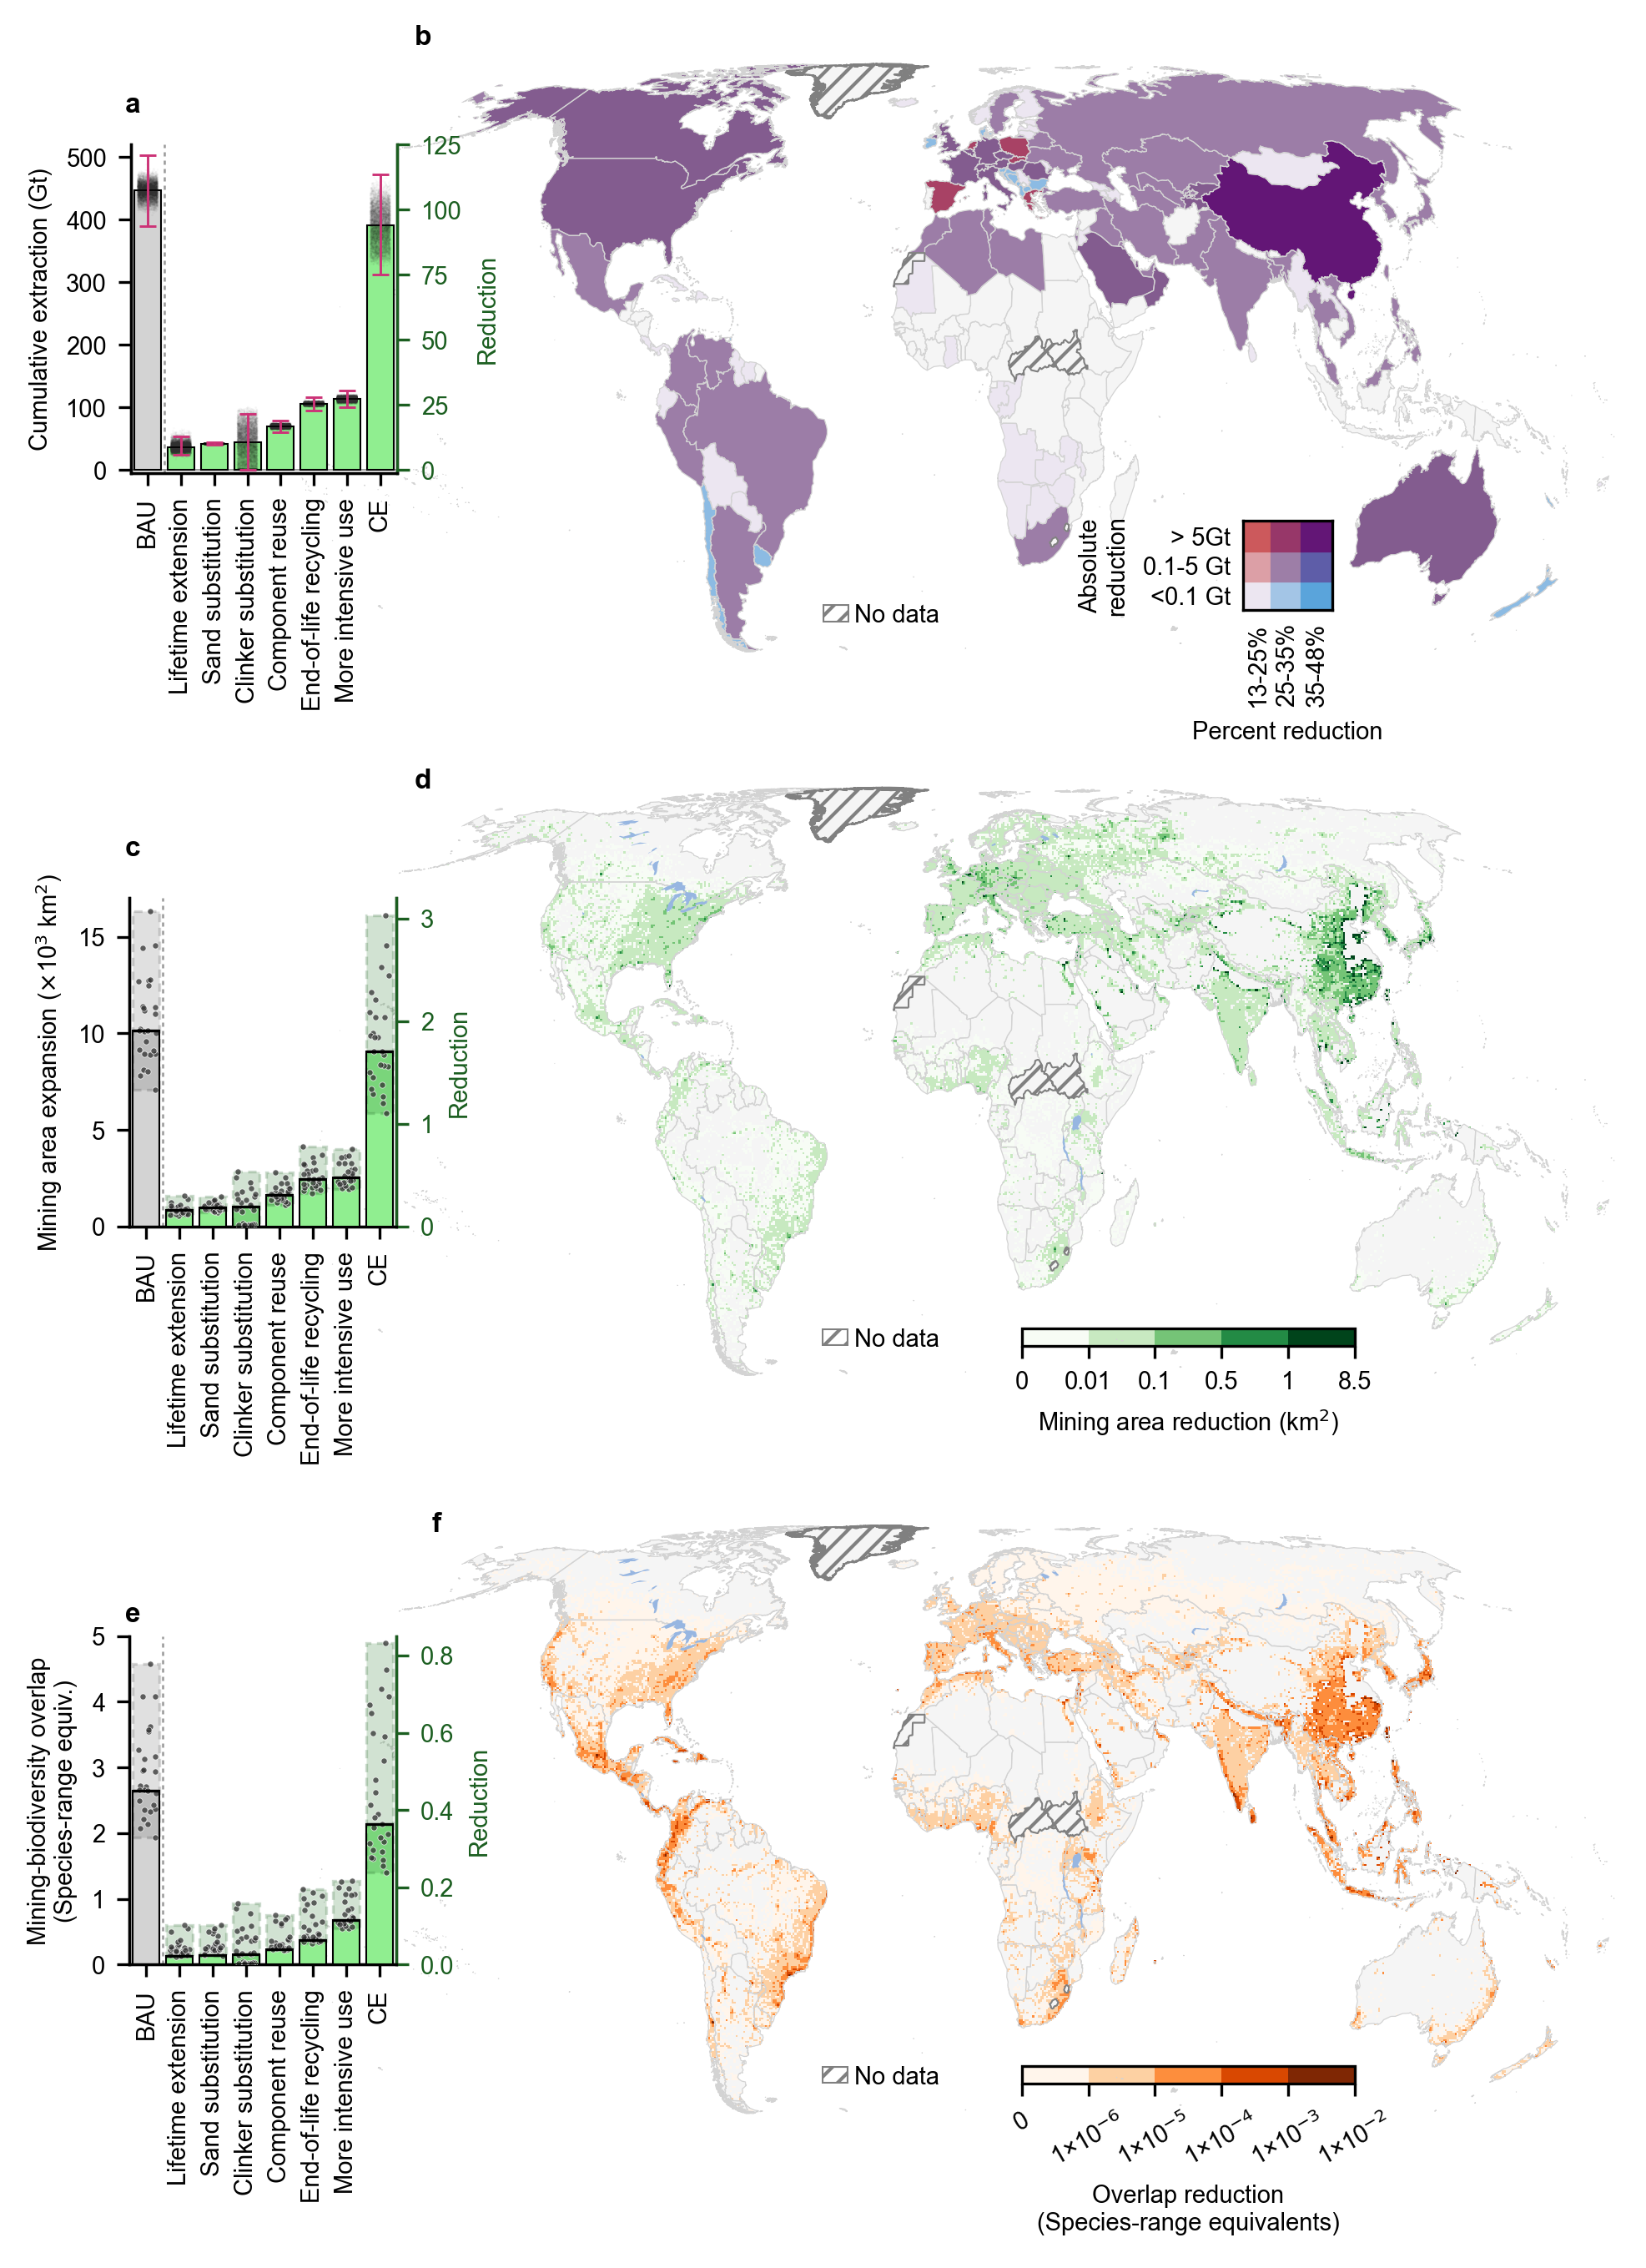

In [ ]:
RED_AX = '#1b5e20'   # colour tying the right axis to the green reduction bars

fig = plt.figure(figsize=(7, 9), constrained_layout=True)
plt.rcParams['font.family'] = 'Arial'

# ---- panel a/b : BAU total (left) + extraction reductions from 0 (right) ----
ax1 = plt.subplot(3, 1, 1, projection=ccrs.EckertIV())
draw_the_background(ax1)
world_map_eck4.plot(column='group_9', cmap=custom_cmap5, edgecolor='none', lw=0.1, ax=ax1)
draw_the_patch(ax1, 3, colorlist_5)

ax1_1 = ax1.inset_axes([-0.12, 0.30, 0.20, 0.55])
axR1 = draw_fig2_bar(extraction_reduction, ax1_1, uncertainty='errorbar',
                      draws=extraction_plot_draws, error_color=SUMMARY_COLOR)
# Retain the established axis limits for comparison with the previous export.
ax1_1.set_ylim(-5.2, 520); ax1_1.set_yticks([0, 100, 200, 300, 400, 500])
ax1_1.set_ylabel('Cumulative extraction (Gt)')
ax1_1.axhline(0, color='0.55', lw=0.4, zorder=2)
axR1.set_ylim(-1.25, 125); axR1.set_yticks([0, 25, 50, 75, 100, 125])
axR1.set_ylabel('Reduction', color=RED_AX, fontsize=9)
axR1.tick_params(axis='y', colors=RED_AX, labelsize=8); axR1.spines['right'].set_color(RED_AX)

# ---- panel c/d : BAU total (left) + mining-area reductions from 0 (right) ----
ax2 = plt.subplot(3, 1, 2, projection=ccrs.EckertIV())
ax2.add_feature(cf.LAKES, zorder=20)
draw_the_background(ax2)
norm_MA_50km = BoundaryNorm([0, 0.01, 0.1, 0.5, 1, 8.5], 256)
im1 = ax2.imshow(np.where(mining_area_reduction_CE_50km, mining_area_reduction_CE_50km, np.nan), cmap='Greens', interpolation='nearest', norm=norm_MA_50km, origin='upper', extent=display_extent_50km, zorder=5, alpha=1.0)

cax2_1 = ax2.inset_axes([0.55, 0.05, 0.25, 0.03])
cbar2_1 = fig.colorbar(im1, cax=cax2_1, orientation='horizontal', label='Mining area reduction (km$^{2}$)')
formatter = FuncFormatter(lambda x, _: f'{x:.2g}')
cbar2_1.ax.xaxis.set_major_formatter(formatter)
cbar2_1.formatter = formatter
cbar2_1.update_ticks()

ax2_1 = ax2.inset_axes([-0.12, 0.25, 0.20, 0.55])
axR2 = draw_fig2_bar(mining_area_reduction / 1e3, ax2_1, uncertainty='band',
                      draws=mining_area_plot_draws / 1e3, point_size=3, point_alpha=0.75,
                      point_edgecolor='white', point_linewidth=0.2, error_color='k', point_zorder=12)
ax2_1.set_ylim(0, 17); ax2_1.set_yticks([0, 5, 10, 15])
ax2_1.set_ylabel('Mining area expansion ($\\times$10$^{3}$ km$^{2}$)')
axR2.set_ylim(0, 3.2); axR2.set_yticks([0, 1, 2, 3])
axR2.set_ylabel('Reduction', color=RED_AX, fontsize=9)
axR2.tick_params(axis='y', colors=RED_AX, labelsize=8); axR2.spines['right'].set_color(RED_AX)

# ---- panel e/f : BAU total (left) + overlap reductions from 0 (right) ----
ax3 = plt.subplot(3, 1, 3, projection=ccrs.EckertIV())
ax3.add_feature(cf.LAKES, zorder=20)
draw_the_background(ax3)
norm_ASR_50km = BoundaryNorm([0, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2], 256)
im3 = ax3.imshow(np.where(overlap_reduction_CE_50km, overlap_reduction_CE_50km, np.nan), cmap='Oranges', interpolation='nearest', norm=norm_ASR_50km, origin='upper', extent=display_extent_50km, zorder=5, alpha=1.0)

cax3_1 = ax3.inset_axes([0.55, 0.05, 0.25, 0.03])
cbar3_1 = fig.colorbar(im3, cax=cax3_1, orientation='horizontal', label='Overlap reduction\n(Species-range equivalents)')
cbar3_1.ax.xaxis.set_major_formatter(FuncFormatter(sci_fmt))
for label in cbar3_1.ax.get_xticklabels():
    label.set_rotation(30)
    label.set_fontsize(9)

ax3_1 = ax3.inset_axes([-0.12, 0.25, 0.20, 0.55])
axR3 = draw_fig2_bar(mining_biodiversity_overlap_reduction, ax3_1, uncertainty='band',
                      draws=mining_biodiversity_plot_draws, point_size=3, point_alpha=0.75,
                      point_edgecolor='white', point_linewidth=0.2, error_color='k', point_zorder=12)
ax3_1.set_ylim(0, 5); ax3_1.set_yticks([0, 1, 2, 3, 4, 5])
ax3_1.set_ylabel('Mining-biodiversity overlap\n(Species-range equiv.)', fontsize=9)
axR3.set_ylim(0, 0.85); axR3.set_yticks([0, 0.2, 0.4, 0.6, 0.8])
axR3.set_ylabel('Reduction', color=RED_AX, fontsize=9)
axR3.tick_params(axis='y', colors=RED_AX, labelsize=8); axR3.spines['right'].set_color(RED_AX)

font_size = 13
fig.text(0.085, 0.97, 'a', fontdict={'size': font_size, 'weight': 'semibold'})
fig.text(0.25, 1.00, 'b', fontdict={'size': font_size, 'weight': 'semibold'})
fig.text(0.085, 0.64, 'c', fontdict={'size': font_size, 'weight': 'semibold'})
fig.text(0.25, 0.67, 'd', fontdict={'size': font_size, 'weight': 'semibold'})
fig.text(0.085, 0.30, 'e', fontdict={'size': font_size, 'weight': 'semibold'})
fig.text(0.26, 0.34, 'f', fontdict={'size': font_size, 'weight': 'semibold'})

# Final PDF width is at most 180 mm; standard text is 5-7 pt at final size.
# Keep text editable by embedding TrueType fonts (no Type 3 glyphs).
from final_figure_export import export_final_figure
export_report = export_final_figure(fig, FIGURES / 'Figure-2')
if plt.get_backend().lower() != 'agg':
    plt.show()


In [ ]:
fig = plt.figure(figsize=(8, 3), constrained_layout=True)
plt.rcParams['font.family'] = 'Arial'

ax1_1 = plt.subplot(1, 3, 1)
axR1 = draw_fig2_bar(extraction_reduction, ax1_1, uncertainty='errorbar',
                      draws=extraction_plot_draws, error_color=SUMMARY_COLOR)
# Retain the established axis limits for comparison with the previous export.
ax1_1.set_ylim(-5.2, 520); ax1_1.set_yticks([0, 100, 200, 300, 400, 500])
ax1_1.set_ylabel('Cumulative extraction (Gt)')
ax1_1.axhline(0, color='0.55', lw=0.4, zorder=2)
axR1.set_ylim(-1.25, 125); axR1.set_yticks([0, 25, 50, 75, 100, 125])
axR1.set_ylabel('Reduction', color=RED_AX, fontsize=9)
axR1.tick_params(axis='y', colors=RED_AX, labelsize=8); axR1.spines['right'].set_color(RED_AX)
ax1_1.set_title('a', loc='left', fontdict={'size': font_size, 'weight': 'semibold'})

ax2_1 = plt.subplot(1, 3, 2)
axR2 = draw_fig2_bar(mining_area_reduction / 1e3, ax2_1, uncertainty='band',
                      draws=mining_area_plot_draws / 1e3, point_size=3, point_alpha=0.75,
                      point_edgecolor='white', point_linewidth=0.2, error_color='k', point_zorder=12)
ax2_1.set_ylim(0, 17); ax2_1.set_yticks([0, 5, 10, 15])
ax2_1.set_ylabel('Mining area expansion ($\\times$10$^{3}$ km$^{2}$)')
axR2.set_ylim(0, 3.2); axR2.set_yticks([0, 1, 2, 3])
axR2.set_ylabel('Reduction', color=RED_AX, fontsize=9)
axR2.tick_params(axis='y', colors=RED_AX, labelsize=8); axR2.spines['right'].set_color(RED_AX)
ax2_1.set_title('c', loc='left', fontdict={'size': font_size, 'weight': 'semibold'})

ax3_1 = plt.subplot(1, 3, 3)
axR3 = draw_fig2_bar(mining_biodiversity_overlap_reduction, ax3_1, uncertainty='band',
                      draws=mining_biodiversity_plot_draws, point_size=3, point_alpha=0.75,
                      point_edgecolor='white', point_linewidth=0.2, error_color='k', point_zorder=12)
ax3_1.set_ylim(0, 5); ax3_1.set_yticks([0, 1, 2, 3, 4, 5])
ax3_1.set_ylabel('Mining-biodiversity overlap\n(Species-range equiv.)', fontsize=9)
axR3.set_ylim(0, 0.85); axR3.set_yticks([0, 0.2, 0.4, 0.6, 0.8])
axR3.set_ylabel('Reduction', color=RED_AX, fontsize=9)
axR3.tick_params(axis='y', colors=RED_AX, labelsize=8); axR3.spines['right'].set_color(RED_AX)
ax3_1.set_title('e', loc='left', fontdict={'size': font_size, 'weight': 'semibold'})

fig.savefig(FIGURES / 'Figure-2-sub.png', dpi=300, bbox_inches='tight')
fig.savefig(FIGURES / 'Figure-2-sub.jpg', dpi=600, bbox_inches='tight')
if plt.get_backend().lower() != 'agg':
    plt.show()